# Dataset Validation and Exploratory Data Analysis

This notebook validates `data/raw/student_learning_data.csv` and explores its structure, distributions, temporal behavior, topic-level performance, student trajectories, and early-warning readiness. It does not modify the raw CSV or train a machine-learning model.

Interpretation is descriptive: observed relationships are reported as associations, not causal effects.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.validate_dataset import EXPECTED_COLUMNS, load_dataset, validation_summary

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'student_learning_data.csv'
df = load_dataset(DATA_PATH)
print(f'Loaded: {DATA_PATH}')

Loaded: C:\Users\Charitha L\OneDrive\Desktop\AI-Academic-Support\data\raw\student_learning_data.csv


## 1. Structure and Basic Descriptives

In [2]:
print('Shape:', df.shape)
print('\nColumn names:')
print(df.columns.tolist())
print('\nData types:')
display(df.dtypes.to_frame('dtype'))
print('\nFirst 10 rows:')
display(df.head(10))
print('\nDescriptive statistics:')
display(df.describe(include='all').transpose())

Shape: (125000, 18)

Column names:
['student_id', 'week', 'subject', 'topic', 'attendance_percentage', 'lectures_attended', 'lectures_conducted', 'quiz_score', 'assignment_score', 'internal_assessment_score', 'lms_login_count', 'lms_resource_views', 'practice_sessions', 'practice_hours', 'questions_attempted', 'questions_correct', 'topic_score', 'academic_difficulty']

Data types:


,dtype
student_id,str
week,int64
subject,str
topic,str
attendance_percentage,float64
lectures_attended,int64
lectures_conducted,int64
quiz_score,float64
assignment_score,float64
internal_assessment_score,float64



First 10 rows:


,student_id,week,subject,topic,attendance_percentage,lectures_attended,lectures_conducted,quiz_score,assignment_score,internal_assessment_score,lms_login_count,lms_resource_views,practice_sessions,practice_hours,questions_attempted,questions_correct,topic_score,academic_difficulty
0,STU-0001,1,Data Structures and Algorithms,Arrays,77.53,2,3,71.09,77.48,87.21,6,11,0,0.0,6,6,79.58,1
1,STU-0001,1,Data Structures and Algorithms,Linked Lists,77.53,2,3,56.84,61.48,64.21,6,11,0,0.0,9,6,61.67,1
2,STU-0001,1,Data Structures and Algorithms,Trees,77.53,2,3,72.81,59.13,58.57,6,11,0,0.0,5,5,67.37,1
3,STU-0001,1,Data Structures and Algorithms,Graph Algorithms,77.53,2,3,58.64,47.77,45.60,6,11,0,0.0,2,1,46.66,1
4,STU-0001,1,Data Structures and Algorithms,Dynamic Programming,77.53,2,3,87.46,82.23,65.91,6,11,0,0.0,9,8,73.07,1
5,STU-0001,1,Database Management Systems,ER Model,77.53,2,3,90.68,64.41,64.76,6,11,0,0.0,5,4,70.41,1
6,STU-0001,1,Database Management Systems,Normalization,77.53,2,3,69.99,82.14,59.76,6,11,0,0.0,4,3,62.90,1
7,STU-0001,1,Database Management Systems,SQL,77.53,2,3,74.46,68.64,80.04,6,11,0,0.0,8,7,73.15,1
8,STU-0001,1,Database Management Systems,SQL Joins,77.53,2,3,58.33,52.69,53.08,6,11,0,0.0,9,7,57.00,1
9,STU-0001,1,Database Management Systems,Transactions,77.53,2,3,65.06,65.06,61.23,6,11,0,0.0,6,5,66.70,1



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,125000,500,STU-0001,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
week,125000.0,NaN,NaN,NaN,5.5,2.872293,1.0,3.0,5.5,8.0,10.0
subject,125000,5,Data Structures and Algorithms,25000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
topic,125000,25,Arrays,5000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
attendance_percentage,125000.0,NaN,NaN,NaN,82.202554,10.294123,48.48,74.9775,82.435,89.86,100.0
lectures_attended,125000.0,NaN,NaN,NaN,2.4274,0.749089,1.0,2.0,2.0,3.0,4.0
lectures_conducted,125000.0,NaN,NaN,NaN,2.9486,0.674953,2.0,2.0,3.0,3.0,4.0
quiz_score,125000.0,NaN,NaN,NaN,61.882123,18.015281,0.0,49.66,62.04,74.38,100.0
assignment_score,125000.0,NaN,NaN,NaN,62.922365,17.617258,0.0,51.02,63.06,75.08,100.0
internal_assessment_score,125000.0,NaN,NaN,NaN,63.204794,17.801945,0.0,51.14,63.43,75.56,100.0


## 2. Structural Validation

In [3]:
summary = validation_summary(df)
print('Missing values by column:')
display(df.isna().sum().to_frame('missing_values'))
print('Duplicate rows:', summary['duplicate_rows'])
print('Unique students:', summary['unique_students'])
print('Unique subjects:', summary['unique_subjects'])
print('Unique topics:', summary['unique_topics'])
print('Unique weeks:', summary['unique_weeks'])

print('Records per student:')
display(summary['records_per_student'].value_counts().sort_index().rename('student_count').to_frame())
print('Records per subject:')
display(summary['records_per_subject'].rename('record_count').to_frame())
print('Records per topic:')
display(summary['records_per_topic'].rename('record_count').to_frame())
print('Records per week:')
display(summary['records_per_week'].rename('record_count').to_frame())

Missing values by column:


,missing_values
student_id,0
week,0
subject,0
topic,0
attendance_percentage,0
lectures_attended,0
lectures_conducted,0
quiz_score,0
assignment_score,0
internal_assessment_score,0


Duplicate rows: 0
Unique students: 500
Unique subjects: 5
Unique topics: 25
Unique weeks: 10
Records per student:


,student_count
250,500


Records per subject:


,record_count
subject,
Computer Networks,25000
Data Structures and Algorithms,25000
Database Management Systems,25000
Mathematics,25000
Operating Systems,25000


Records per topic:


,record_count
topic,
Arrays,5000
CPU Scheduling,5000
Calculus,5000
Deadlocks,5000
Discrete Mathematics,5000
Dynamic Programming,5000
ER Model,5000
File Systems,5000
Graph Algorithms,5000


Records per week:


,record_count
week,
1,12500
2,12500
3,12500
4,12500
5,12500
6,12500
7,12500
8,12500
9,12500


In [4]:
student_structure = df.groupby('student_id').agg(
    weeks=('week', 'nunique'),
    subjects=('subject', 'nunique'),
    topics=('topic', 'nunique'),
    records=('student_id', 'size'),
)
student_structure['valid_structure'] = (
    student_structure['weeks'].eq(10)
    & student_structure['subjects'].eq(5)
    & student_structure['topics'].eq(25)
    & student_structure['records'].eq(250)
)
display(student_structure.head())
print('Students with expected 10 weeks:', summary['all_students_have_10_weeks'])
print('Students with expected 5 subjects:', summary['all_students_have_5_subjects'])
print('Students with expected 25 topics:', summary['all_students_have_25_topics'])
print('Students with expected 250 records:', bool(student_structure['records'].eq(250).all()))
print('All structural checks pass:', bool(student_structure['valid_structure'].all()))

,weeks,subjects,topics,records,valid_structure
student_id,,,,,
STU-0001,10,5,25,250,True
STU-0002,10,5,25,250,True
STU-0003,10,5,25,250,True
STU-0004,10,5,25,250,True
STU-0005,10,5,25,250,True


Students with expected 10 weeks: True
Students with expected 5 subjects: True
Students with expected 25 topics: True
Students with expected 250 records: True
All structural checks pass: True


## 3. Academic Difficulty Distribution

,count,percentage
academic_difficulty,,
Low,162,32.4
Moderate,284,56.8
High,54,10.8


C:\Users\Charitha L\AppData\Local\Temp\ipykernel_17556\2090582686.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=student_targets, x='academic_difficulty', order=[0, 1, 2], palette='Set2')


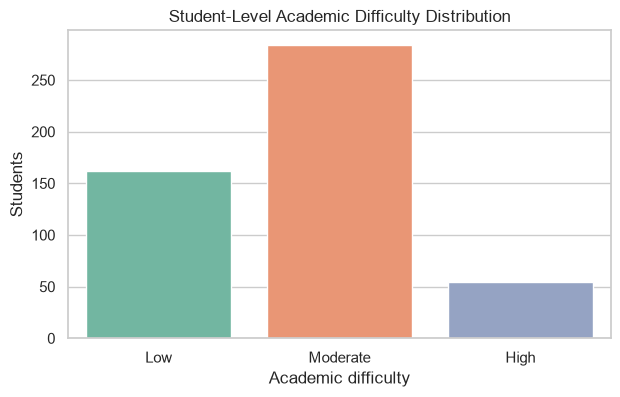

In [5]:
difficulty_labels = {0: 'Low', 1: 'Moderate', 2: 'High'}
student_targets = df[['student_id', 'academic_difficulty']].drop_duplicates()
difficulty_counts = student_targets['academic_difficulty'].value_counts().sort_index().rename(index=difficulty_labels)
difficulty_percentages = (difficulty_counts / difficulty_counts.sum() * 100).round(2)
display(pd.DataFrame({'count': difficulty_counts, 'percentage': difficulty_percentages}))

plt.figure(figsize=(7, 4))
sns.countplot(data=student_targets, x='academic_difficulty', order=[0, 1, 2], palette='Set2')
plt.xticks([0, 1, 2], ['Low', 'Moderate', 'High'])
plt.title('Student-Level Academic Difficulty Distribution')
plt.xlabel('Academic difficulty')
plt.ylabel('Students')
plt.show()

## 4. Numerical Variables and Distributions

,count,mean,std,min,25%,50%,75%,max
attendance_percentage,125000.0,82.202554,10.294123,48.48,74.9775,82.435,89.8600,100.00
quiz_score,125000.0,61.882123,18.015281,0.00,49.6600,62.040,74.3800,100.00
assignment_score,125000.0,62.922365,17.617258,0.00,51.0200,63.060,75.0800,100.00
internal_assessment_score,125000.0,63.204794,17.801945,0.00,51.1400,63.430,75.5600,100.00
lms_login_count,125000.0,3.776000,2.530351,0.00,2.0000,4.000,6.0000,13.00
lms_resource_views,125000.0,7.828000,5.545544,0.00,3.0000,7.000,12.0000,29.00
practice_sessions,125000.0,2.352000,1.604031,0.00,1.0000,2.000,3.0000,8.00
practice_hours,125000.0,1.434578,1.077815,0.00,0.5700,1.300,2.0825,6.05
questions_attempted,125000.0,9.816968,3.166562,1.00,8.0000,10.000,12.0000,26.00
questions_correct,125000.0,6.897912,2.886128,0.00,5.0000,7.000,9.0000,22.00


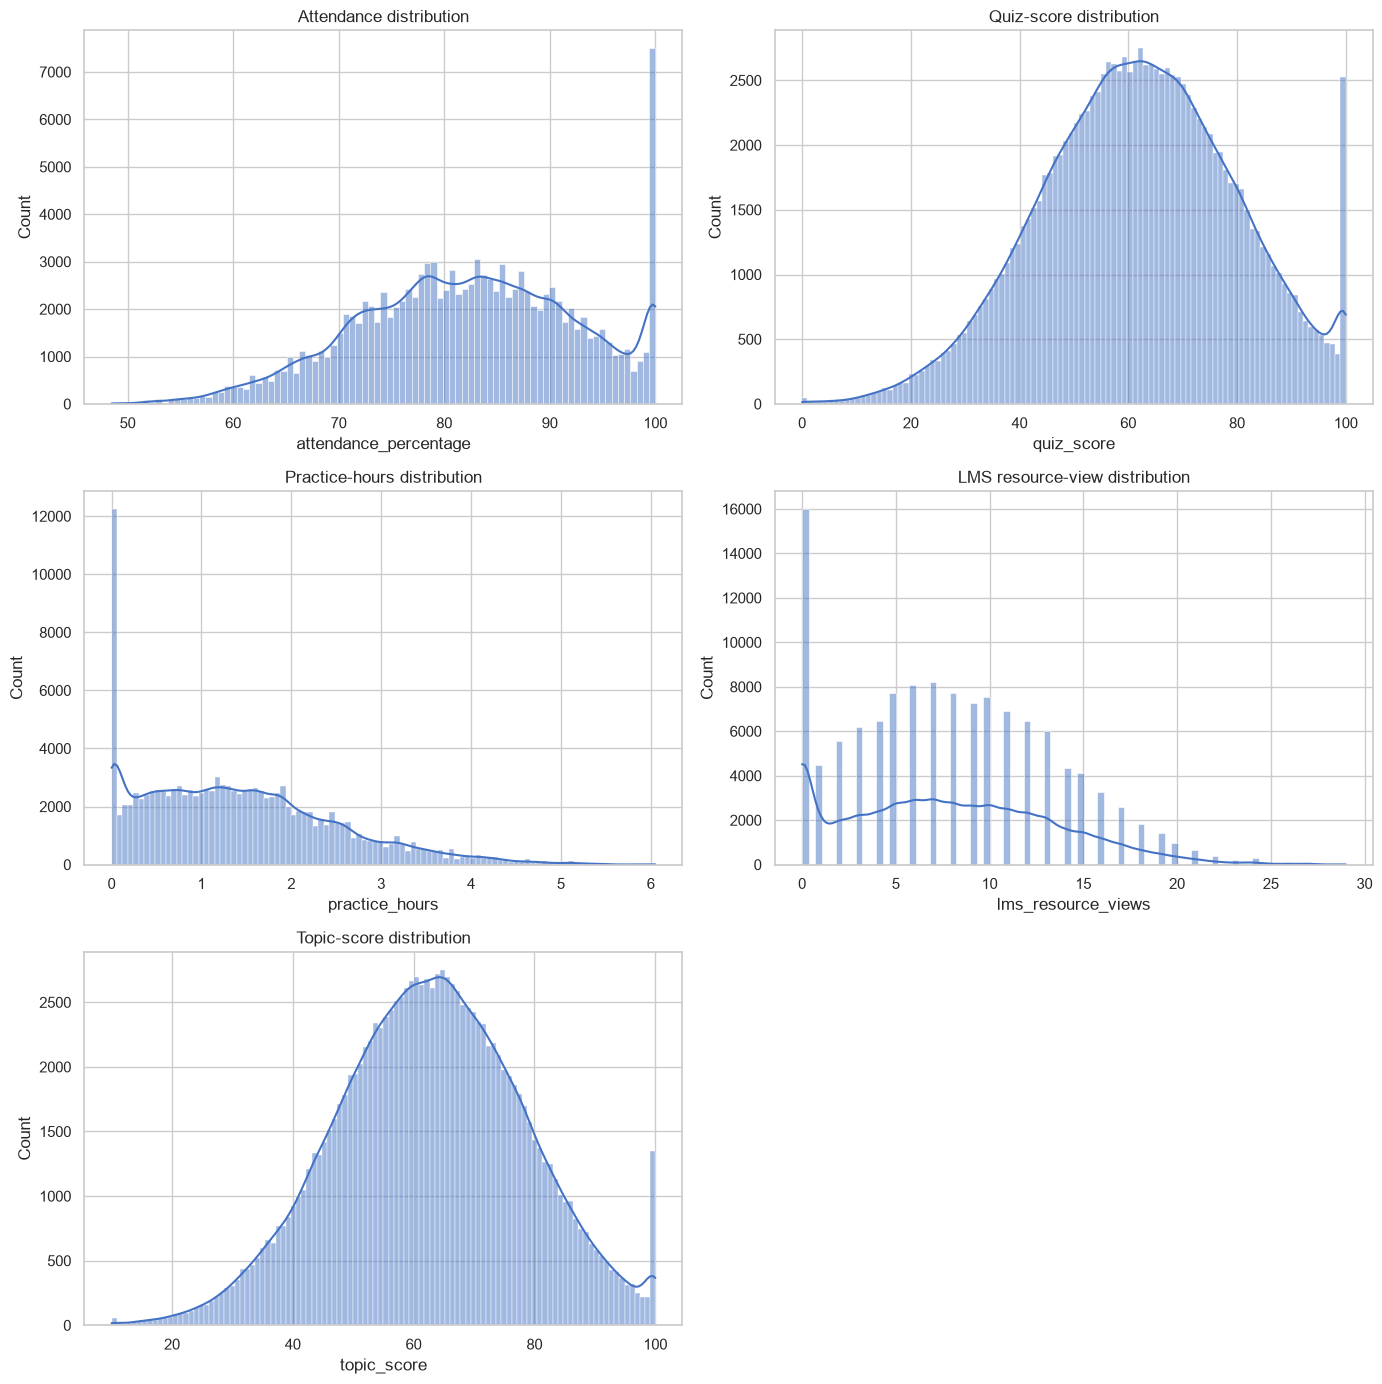

In [6]:
numeric_columns = [
    'attendance_percentage', 'quiz_score', 'assignment_score',
    'internal_assessment_score', 'lms_login_count', 'lms_resource_views',
    'practice_sessions', 'practice_hours', 'questions_attempted',
    'questions_correct', 'topic_score'
]
display(df[numeric_columns].describe().transpose())

plot_columns = {
    'attendance_percentage': 'Attendance distribution',
    'quiz_score': 'Quiz-score distribution',
    'practice_hours': 'Practice-hours distribution',
    'lms_resource_views': 'LMS resource-view distribution',
    'topic_score': 'Topic-score distribution',
}
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
for axis, (column, title) in zip(axes.flat, plot_columns.items()):
    sns.histplot(data=df, x=column, kde=True, ax=axis, color='#4472C4')
    axis.set_title(title)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

## 5. Relationships and Associations

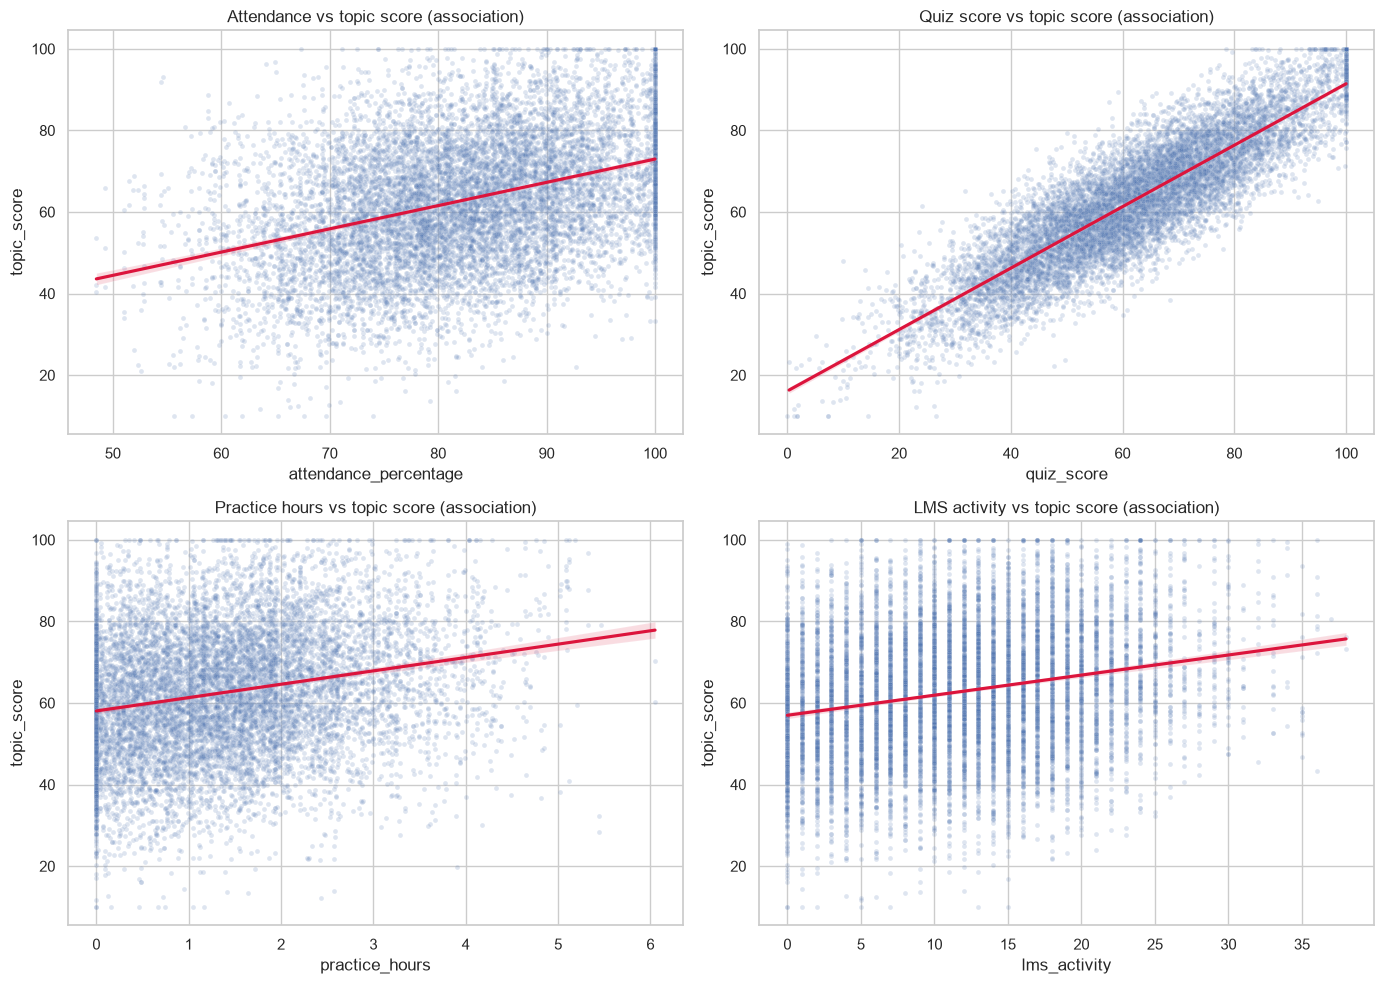

Pearson correlations with topic_score:


,correlation
topic_score,1.000000
quiz_score,0.868193
attendance_percentage,0.391163
lms_activity,0.231971
practice_hours,0.223564


In [7]:
df['lms_activity'] = df['lms_login_count'] + df['lms_resource_views']
relationship_specs = [
    ('attendance_percentage', 'topic_score', 'Attendance vs topic score'),
    ('quiz_score', 'topic_score', 'Quiz score vs topic score'),
    ('practice_hours', 'topic_score', 'Practice hours vs topic score'),
    ('lms_activity', 'topic_score', 'LMS activity vs topic score'),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for axis, (x_column, y_column, title) in zip(axes.flat, relationship_specs):
    sns.scatterplot(data=df.sample(min(10000, len(df)), random_state=42), x=x_column, y=y_column, alpha=0.18, s=12, ax=axis)
    sns.regplot(data=df.sample(min(5000, len(df)), random_state=42), x=x_column, y=y_column, scatter=False, color='crimson', ax=axis)
    axis.set_title(title + ' (association)')
plt.tight_layout()
plt.show()

print('Pearson correlations with topic_score:')
display(df[['attendance_percentage', 'quiz_score', 'practice_hours', 'lms_activity', 'topic_score']].corr()['topic_score'].sort_values(ascending=False).to_frame('correlation'))

C:\Users\Charitha L\AppData\Local\Temp\ipykernel_17556\236291530.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='academic_difficulty', y='topic_score', order=[0, 1, 2], ax=axes[0], palette='Set2')
C:\Users\Charitha L\AppData\Local\Temp\ipykernel_17556\236291530.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Low', 'Moderate', 'High'])
C:\Users\Charitha L\AppData\Local\Temp\ipykernel_17556\236291530.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='academic_difficulty', y='attendance_percentage', order=[0, 1, 2], 

C:\Users\Charitha L\AppData\Local\Temp\ipykernel_17556\236291530.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(['Low', 'Moderate', 'High'])


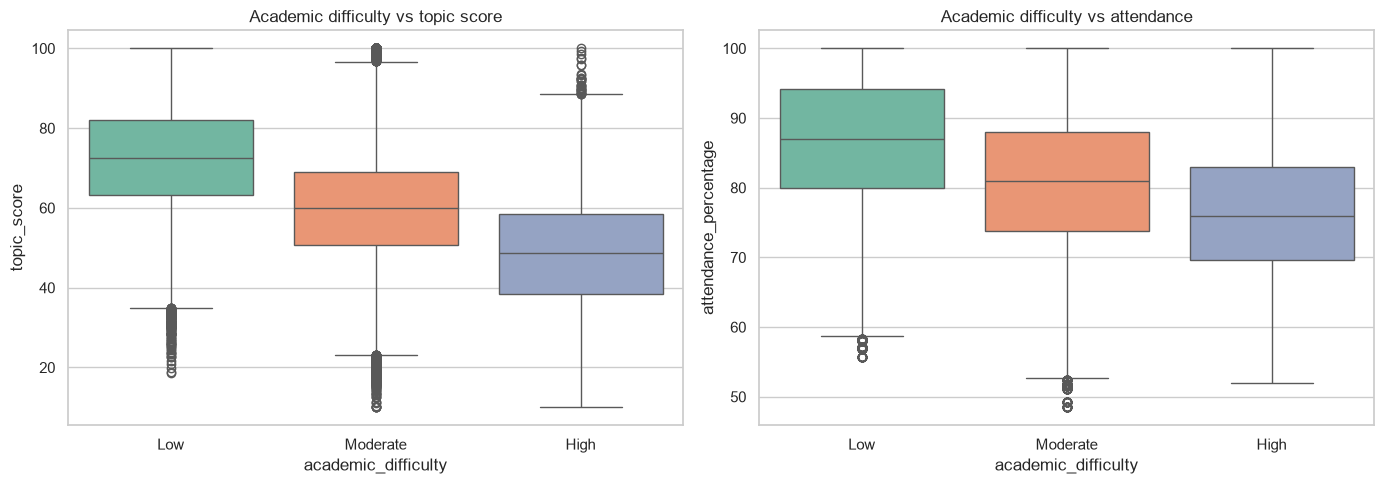

topic_score               attendance_percentage         \
                           mean median    std                  mean median   
academic_difficulty                                                          
0                         72.41  72.54  13.67                 86.60  86.97   
1                         59.95  59.93  13.64                 80.83  80.96   
2                         48.55  48.58  14.51                 76.23  75.97   

                           
                      std  
academic_difficulty        
0                    9.46  
1                    9.92  
2                    9.57

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='academic_difficulty', y='topic_score', order=[0, 1, 2], ax=axes[0], palette='Set2')
axes[0].set_xticklabels(['Low', 'Moderate', 'High'])
axes[0].set_title('Academic difficulty vs topic score')
sns.boxplot(data=df, x='academic_difficulty', y='attendance_percentage', order=[0, 1, 2], ax=axes[1], palette='Set2')
axes[1].set_xticklabels(['Low', 'Moderate', 'High'])
axes[1].set_title('Academic difficulty vs attendance')
plt.tight_layout()
plt.show()

display(df.groupby('academic_difficulty')[['topic_score', 'attendance_percentage']].agg(['mean', 'median', 'std']).round(2))

## 6. Temporal Behavior

,average_topic_score,average_quiz_score,average_attendance,average_practice_hours,average_practice_sessions
week,,,,,
1,62.24,61.38,81.82,1.43,2.36
2,62.32,61.22,81.85,1.49,2.39
3,62.35,61.53,82.05,1.45,2.32
4,62.38,61.56,82.21,1.37,2.28
5,62.49,61.44,81.66,1.36,2.28
6,63.01,62.16,82.30,1.48,2.38
7,62.82,61.87,82.23,1.42,2.34
8,63.38,62.71,82.78,1.43,2.35
9,63.34,62.53,82.53,1.50,2.44


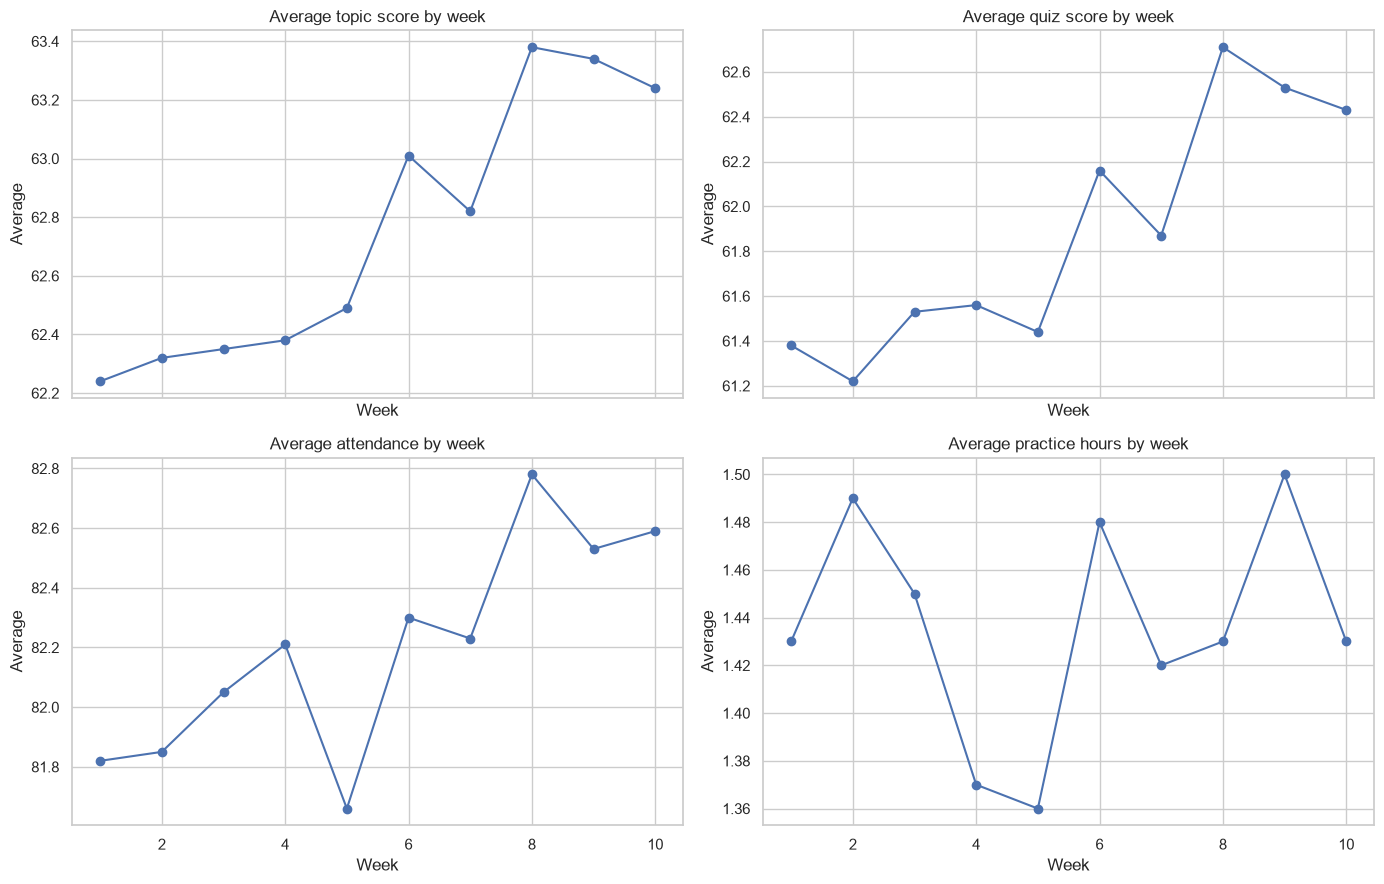

In [9]:
weekly_summary = df.groupby('week').agg(
    average_topic_score=('topic_score', 'mean'),
    average_quiz_score=('quiz_score', 'mean'),
    average_attendance=('attendance_percentage', 'mean'),
    average_practice_hours=('practice_hours', 'mean'),
    average_practice_sessions=('practice_sessions', 'mean'),
).round(2)
display(weekly_summary)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for axis, column, title in zip(axes.flat, weekly_summary.columns[:4], [
    'Average topic score by week', 'Average quiz score by week',
    'Average attendance by week', 'Average practice hours by week'
]):
    axis.plot(weekly_summary.index, weekly_summary[column], marker='o')
    axis.set_title(title)
    axis.set_xlabel('Week')
    axis.set_ylabel('Average')
plt.tight_layout()
plt.show()

## 7. Topic-Level Performance

Average topic_score for every topic, lowest first:


average_topic_score  \
subject                        topic                                        
Data Structures and Algorithms Dynamic Programming              58.926502   
Mathematics                    Calculus                         59.533060   
Operating Systems              Deadlocks                        60.062452   
Database Management Systems    Transactions                     60.324602   
Data Structures and Algorithms Graph Algorithms                 60.526548   
Mathematics                    Discrete Mathematics             60.638916   
Operating Systems              Memory Management                60.836198   
Computer Networks              Network Security                 60.850150   
                               Routing                          61.911764   
Mathematics                    Linear Algebra                   62.319602   
Operating Systems              CPU Scheduling                   62.471008   
Database Management Systems    SQL Joins                        62.638844   
Computer Networks              Transport Layer                  62.800010   
Data Structures and Algorithms Trees                            63.020124   
Mathematics                    Probability                      63.107040   
Database Management Systems    Normalization                    63.298294   
Operating Systems              Processes and Threads            63.955074   
Computer Networks              IP Addressing                    64.544092   
Operating Systems              File Systems                     64.590626   
Mathematics                    Statistics                       64.802596   
Database Management Systems    SQL                              64.859182   
Data Structures and Algorithms Linked Lists                     64.906598   
                               Arrays                           65.864096   
Database Management Systems    ER Model                         65.954030   
Computer Networks              OSI and TCP/IP                   66.192552   

                                                      score_std  records  
subject                        topic                                      
Data Structures and Algorithms Dynamic Programming    15.125305     5000  
Mathematics                    Calculus               16.072961     5000  
Operating Systems              Deadlocks              15.224150     5000  
Database Management Systems    Transactions           15.563329     5000  
Data Structures and Algorithms Graph Algorithms       14.873502     5000  
Mathematics                    Discrete Mathematics   16.006348     5000  
Operating Systems              Memory Management      15.041330     5000  
Computer Networks              Network Security       15.184081     5000  
                               Routing                15.723136     5000  
Mathematics                    Linear Algebra         15.972802     5000  
Operating Systems              CPU Scheduling         15.406149     5000  
Database Management Systems    SQL Joins              15.825283     5000  
Computer Networks              Transport Layer        15.384931     5000  
Data Structures and Algorithms Trees                  15.418749     5000  
Mathematics                    Probability            15.967662     5000  
Database Management Systems    Normalization          15.740295     5000  
Operating Systems              Processes and Threads  15.042571     5000  
Computer Networks              IP Addressing          15.615125     5000  
Operating Systems              File Systems           15.395875     5000  
Mathematics                    Statistics             15.712527     5000  
Database Management Systems    SQL                    15.751496     5000  
Data Structures and Algorithms Linked Lists           15.672353     5000  
                               Arrays                 15.486347     5000  
Database Management Systems    ER Model               15.450443     5000  
Computer Networks       

Lower-performing topics:


average_topic_score  \
subject                        topic                                       
Data Structures and Algorithms Dynamic Programming             58.926502   
Mathematics                    Calculus                        59.533060   
Operating Systems              Deadlocks                       60.062452   
Database Management Systems    Transactions                    60.324602   
Data Structures and Algorithms Graph Algorithms                60.526548   
Mathematics                    Discrete Mathematics            60.638916   
Operating Systems              Memory Management               60.836198   
Computer Networks              Network Security                60.850150   
                               Routing                         61.911764   
Mathematics                    Linear Algebra                  62.319602   

                                                     score_std  records  
subject                        topic                                     
Data Structures and Algorithms Dynamic Programming   15.125305     5000  
Mathematics                    Calculus              16.072961     5000  
Operating Systems              Deadlocks             15.224150     5000  
Database Management Systems    Transactions          15.563329     5000  
Data Structures and Algorithms Graph Algorithms      14.873502     5000  
Mathematics                    Discrete Mathematics  16.006348     5000  
Operating Systems              Memory Management     15.041330     5000  
Computer Networks              Network Security      15.184081     5000  
                               Routing               15.723136     5000  
Mathematics                    Linear Algebra        15.972802     5000

Subject-wise topic performance:


subject,Computer Networks,Data Structures and Algorithms,Database Management Systems,Mathematics,Operating Systems
topic,,,,,
Arrays,NaN,65.86,NaN,NaN,NaN
CPU Scheduling,NaN,NaN,NaN,NaN,62.47
Calculus,NaN,NaN,NaN,59.53,NaN
Deadlocks,NaN,NaN,NaN,NaN,60.06
Discrete Mathematics,NaN,NaN,NaN,60.64,NaN
Dynamic Programming,NaN,58.93,NaN,NaN,NaN
ER Model,NaN,NaN,65.95,NaN,NaN
File Systems,NaN,NaN,NaN,NaN,64.59
Graph Algorithms,NaN,60.53,NaN,NaN,NaN


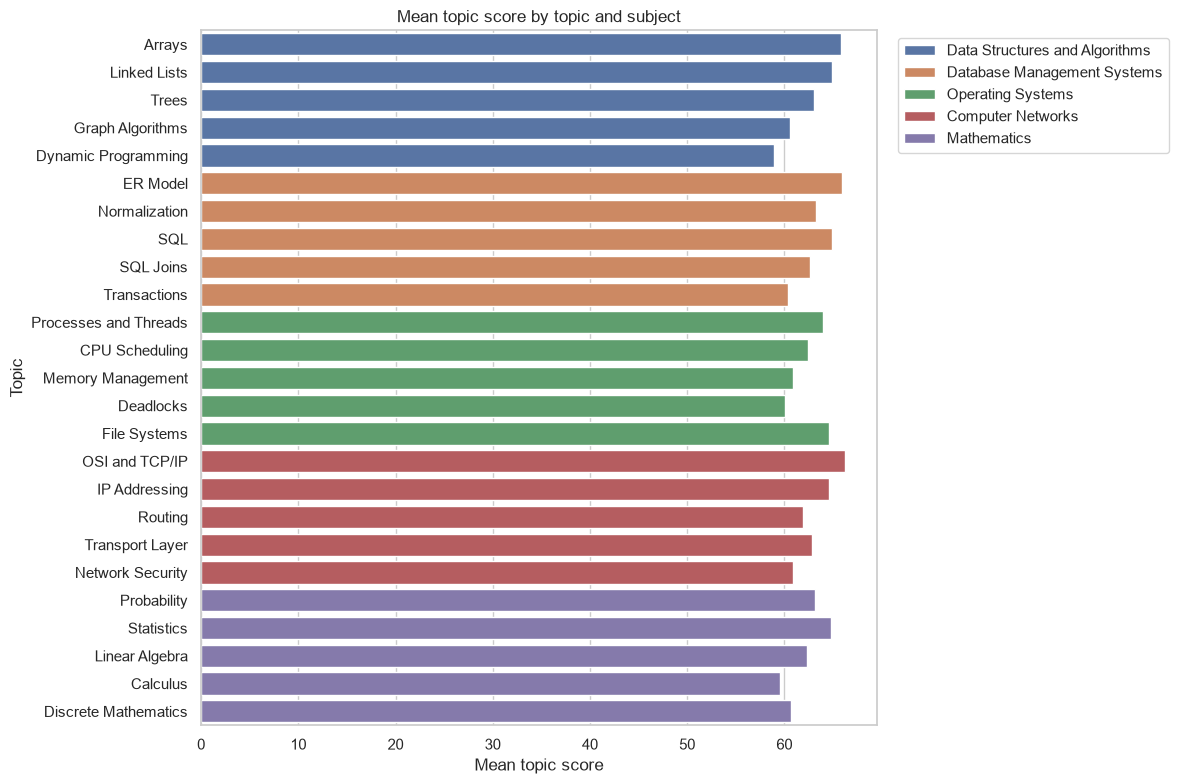

In [10]:
topic_performance = df.groupby(['subject', 'topic']).agg(
    average_topic_score=('topic_score', 'mean'),
    score_std=('topic_score', 'std'),
    records=('topic_score', 'size'),
).sort_values('average_topic_score')
print('Average topic_score for every topic, lowest first:')
display(topic_performance)

print('Lower-performing topics:')
display(topic_performance.head(10))

subject_topic_table = df.pivot_table(index='topic', columns='subject', values='topic_score', aggfunc='mean').round(2)
print('Subject-wise topic performance:')
display(subject_topic_table)

plt.figure(figsize=(12, 8))
sns.barplot(data=df, y='topic', x='topic_score', hue='subject', estimator='mean', errorbar=None, dodge=False)
plt.title('Mean topic score by topic and subject')
plt.xlabel('Mean topic score')
plt.ylabel('Topic')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 8. Student-Level Trajectories

In [11]:
student_weekly = df.groupby(['student_id', 'week']).agg(
    topic_score=('topic_score', 'mean'),
    quiz_score=('quiz_score', 'mean'),
    attendance=('attendance_percentage', 'mean'),
    practice_hours=('practice_hours', 'mean'),
).reset_index()

def student_slope(group, column):
    return np.polyfit(group['week'], group[column], 1)[0]

student_trends = student_weekly.groupby('student_id').apply(
    lambda group: pd.Series({
        'topic_score_slope': student_slope(group, 'topic_score'),
        'quiz_score_slope': student_slope(group, 'quiz_score'),
        'attendance_slope': student_slope(group, 'attendance'),
    }), include_groups=False
).sort_values('topic_score_slope')
student_trends['trajectory'] = pd.cut(
    student_trends['topic_score_slope'],
    bins=[-np.inf, -0.35, 0.35, np.inf],
    labels=['Declining', 'Stable', 'Improving']
)
print('Student trajectory counts based on topic-score slope:')
display(student_trends['trajectory'].value_counts().reindex(['Improving', 'Stable', 'Declining']))
print('Examples of improving students:')
display(student_trends[student_trends['trajectory'].eq('Improving')].tail(5))
print('Examples of declining students:')
display(student_trends[student_trends['trajectory'].eq('Declining')].head(5))
print('Examples of relatively stable students:')
display(student_trends[student_trends['trajectory'].eq('Stable')].head(5))

Student trajectory counts based on topic-score slope:


trajectory
Improving    196
Stable       144
Declining    160
Name: count, dtype: int64

Examples of improving students:


,topic_score_slope,quiz_score_slope,attendance_slope,trajectory
student_id,,,,
STU-0492,2.654039,2.615813,1.263879,Improving
STU-0064,2.704839,2.403205,1.605818,Improving
STU-0131,2.761493,2.954339,2.559515,Improving
STU-0059,2.789576,2.780036,2.010970,Improving
STU-0162,2.848310,2.796812,1.985636,Improving


Examples of declining students:


,topic_score_slope,quiz_score_slope,attendance_slope,trajectory
student_id,,,,
STU-0062,-3.457120,-3.651338,-2.069333,Declining
STU-0135,-3.134987,-2.808858,-2.627152,Declining
STU-0340,-3.074482,-3.161859,-2.331091,Declining
STU-0036,-3.021697,-3.081280,-1.372909,Declining
STU-0221,-2.877205,-2.946301,-2.933455,Declining


Examples of relatively stable students:


,topic_score_slope,quiz_score_slope,attendance_slope,trajectory
student_id,,,,
STU-0086,-0.348305,-0.595605,-0.281152,Stable
STU-0304,-0.345777,-0.147537,-0.105455,Stable
STU-0265,-0.345149,-0.320291,-0.082303,Stable
STU-0194,-0.341573,-0.332967,0.053576,Stable
STU-0205,-0.340092,-0.458242,-0.695091,Stable


## 9. Target Consistency and Early-Warning Readiness

In [12]:
target_consistency = df.groupby('student_id')['academic_difficulty'].nunique()
print('Academic-difficulty values per student:')
display(target_consistency.value_counts().sort_index().rename('student_count').to_frame())
print('Is academic_difficulty constant for every student?', bool(target_consistency.eq(1).all()))

early_data = df[df['week'].between(1, 6)].copy()
future_data = df[df['week'].between(7, 10)].copy()
print('Early data rows (weeks 1-6):', len(early_data))
print('Future outcome-window rows (weeks 7-10):', len(future_data))
print('Target exists for every student in early data:', early_data['academic_difficulty'].notna().all())
print('Current target construction uses weeks 8-10, not week 7.')
print('Strict weeks 7-10 target construction would require a separate target definition; do not overwrite the raw CSV.')

early_student_features = early_data.groupby('student_id').agg(
    early_topic_score=('topic_score', 'mean'),
    early_attendance=('attendance_percentage', 'mean'),
    early_quiz_score=('quiz_score', 'mean'),
    early_practice_hours=('practice_hours', 'mean'),
).join(student_targets.set_index('student_id'))
display(early_student_features.head())

Academic-difficulty values per student:


,student_count
academic_difficulty,
1,500


Is academic_difficulty constant for every student? True
Early data rows (weeks 1-6): 75000
Future outcome-window rows (weeks 7-10): 50000
Target exists for every student in early data: True
Current target construction uses weeks 8-10, not week 7.
Strict weeks 7-10 target construction would require a separate target definition; do not overwrite the raw CSV.


,early_topic_score,early_attendance,early_quiz_score,early_practice_hours,academic_difficulty
student_id,,,,,
STU-0001,67.309933,73.925000,66.977733,0.901667,1
STU-0002,62.446933,83.905000,61.814400,0.898333,0
STU-0003,55.198333,68.905000,52.594267,0.390000,1
STU-0004,71.562867,98.591667,71.971667,1.531667,1
STU-0005,62.216867,75.915000,59.952933,1.050000,1


## 10. Leakage Risks and Readiness Assessment

### Leakage checklist

- **Repeated student records:** Each student appears in many rows. A random row-level split could place the same student's history in both training and test sets, inflating estimated generalization.
- **Repeated subject/topic records:** Each student-topic combination repeats across weeks. Topic-specific and student-specific patterns can therefore cross a row-level split.
- **Temporal information:** Weeks encode ordering. Features must be built only from weeks 1–6 for the requested early experiment, while weeks 7–10 remain unavailable to the predictor.
- **Target construction:** The current `academic_difficulty` target was constructed from weeks 8–10. It is constant within student, but it is future information and must never be an input feature.
- **Split strategy:** Use a student-level split when evaluating generalization to unseen students. A time-based split is also needed when evaluating deployment over time; the exact design should be fixed before modeling.

### Concise EDA report

**Dataset strengths:** The dataset is complete, structured, reproducible, and balanced across students, weeks, subjects, and topics. It contains multiple engagement and performance indicators, student-level variation, topic-level variation, and temporal observations suitable for exploratory early-warning research.

**Dataset limitations:** It is synthetic and therefore cannot establish that these patterns hold for a real university population. The variables are simulated, the target is student-level rather than topic-level, and the observed relationships should not be interpreted as causal. The generated target uses weeks 8–10, whereas the requested future window is weeks 7–10.

**Class imbalance:** The class-count table above should be inspected before modeling. If the classes are uneven, use stratified student-level evaluation and report per-class metrics rather than relying on accuracy alone.

**ML readiness:** The raw dataset is structurally ready for preprocessing experiments, but it is not ready for a trustworthy model without defining the unit of prediction, constructing early-window aggregates, confirming the target window, and choosing leakage-resistant validation.

**Next preprocessing and target engineering:** Keep the raw CSV unchanged. Create a separate processed table with one row per student for weeks 1–6, aggregate early indicators, exclude future-derived fields and the target from predictors, and decide whether to retain the current weeks 8–10 target or construct a documented weeks 7–10 outcome. Use student-level and, where appropriate, time-aware splits.